# 4. SHAP del ganador e interacciones no lineales

Recalcula las explicaciones del ganador real y un análisis explícito de interaccionesTreeSHAP de XGBoost. Este complemento no cambia el ganador y no atribuye causalidad.

In [1]:
from pathlib import Path
import os,sys,json,subprocess,time
import pandas as pd
from IPython.display import display,Image,Markdown
ROOT=Path.cwd()
if not (ROOT/'src').is_dir(): ROOT=ROOT.parent
assert (ROOT/'src/run_analysis.py').exists(), 'Abra el notebook dentro del proyecto'
os.environ['MPLCONFIGDIR']=str(ROOT/'tmp/matplotlib')
os.environ['XDG_CACHE_HOME']=str(ROOT/'tmp/cache')
sys.path.insert(0,str(ROOT/'src'))
def run_script(name,*args):
    started=time.perf_counter()
    result=subprocess.run([sys.executable,str(ROOT/'src'/name),*map(str,args)],cwd=ROOT,text=True,capture_output=True)
    (ROOT/'reports').mkdir(exist_ok=True)
    (ROOT/'reports'/f'notebook_{name}_{Path(str(args[-1])).name if args else "run"}.log').write_text(result.stdout+result.stderr)
    print(result.stdout[-4500:])
    if result.returncode: print(result.stderr); result.check_returncode()
    print(f'Ejecución real completada en {time.perf_counter()-started:.1f} segundos')
def show(name): display(Image(filename=str(ROOT/'reports/figures'/name)))
def table(name): display(pd.read_csv(ROOT/'reports/tables'/name).head(20))
def results(): return json.loads((ROOT/'reports/results.json').read_text())
print('Python:',sys.version.split()[0], '| ejecutable del kernel:',sys.executable)


Python: 3.12.14 | ejecutable del kernel: ${PROJECT_ROOT}/.venv/bin/python


## Explicación real
SHAP explica el score antes de calibrar. Se documentan referencia, muestra y unidades; las probabilidades calibradas son distintas. Los dos casos son extremos correctamente clasificados y se presentan sin identificadores personales.

Cohorte y particiones 13105 3439
Completado shap CatBoost

Ejecución real completada en 5.1 segundos
Ganador: CatBoost | unidades: log-odds
Residuo aditividad: 6.217248937900877e-15


,variable,mean_abs_shap
0,edad,1.057028
1,log_gasto_pc,0.444137
2,prop_publicas,0.223087
3,lengua_materna,0.146127
4,electricidad,0.136771
5,rural,0.125100
6,log_ingreso_pc,0.110146
7,altitud,0.094581
8,internet_hogar,0.080215
9,ratio_alumnos_docente,0.054356


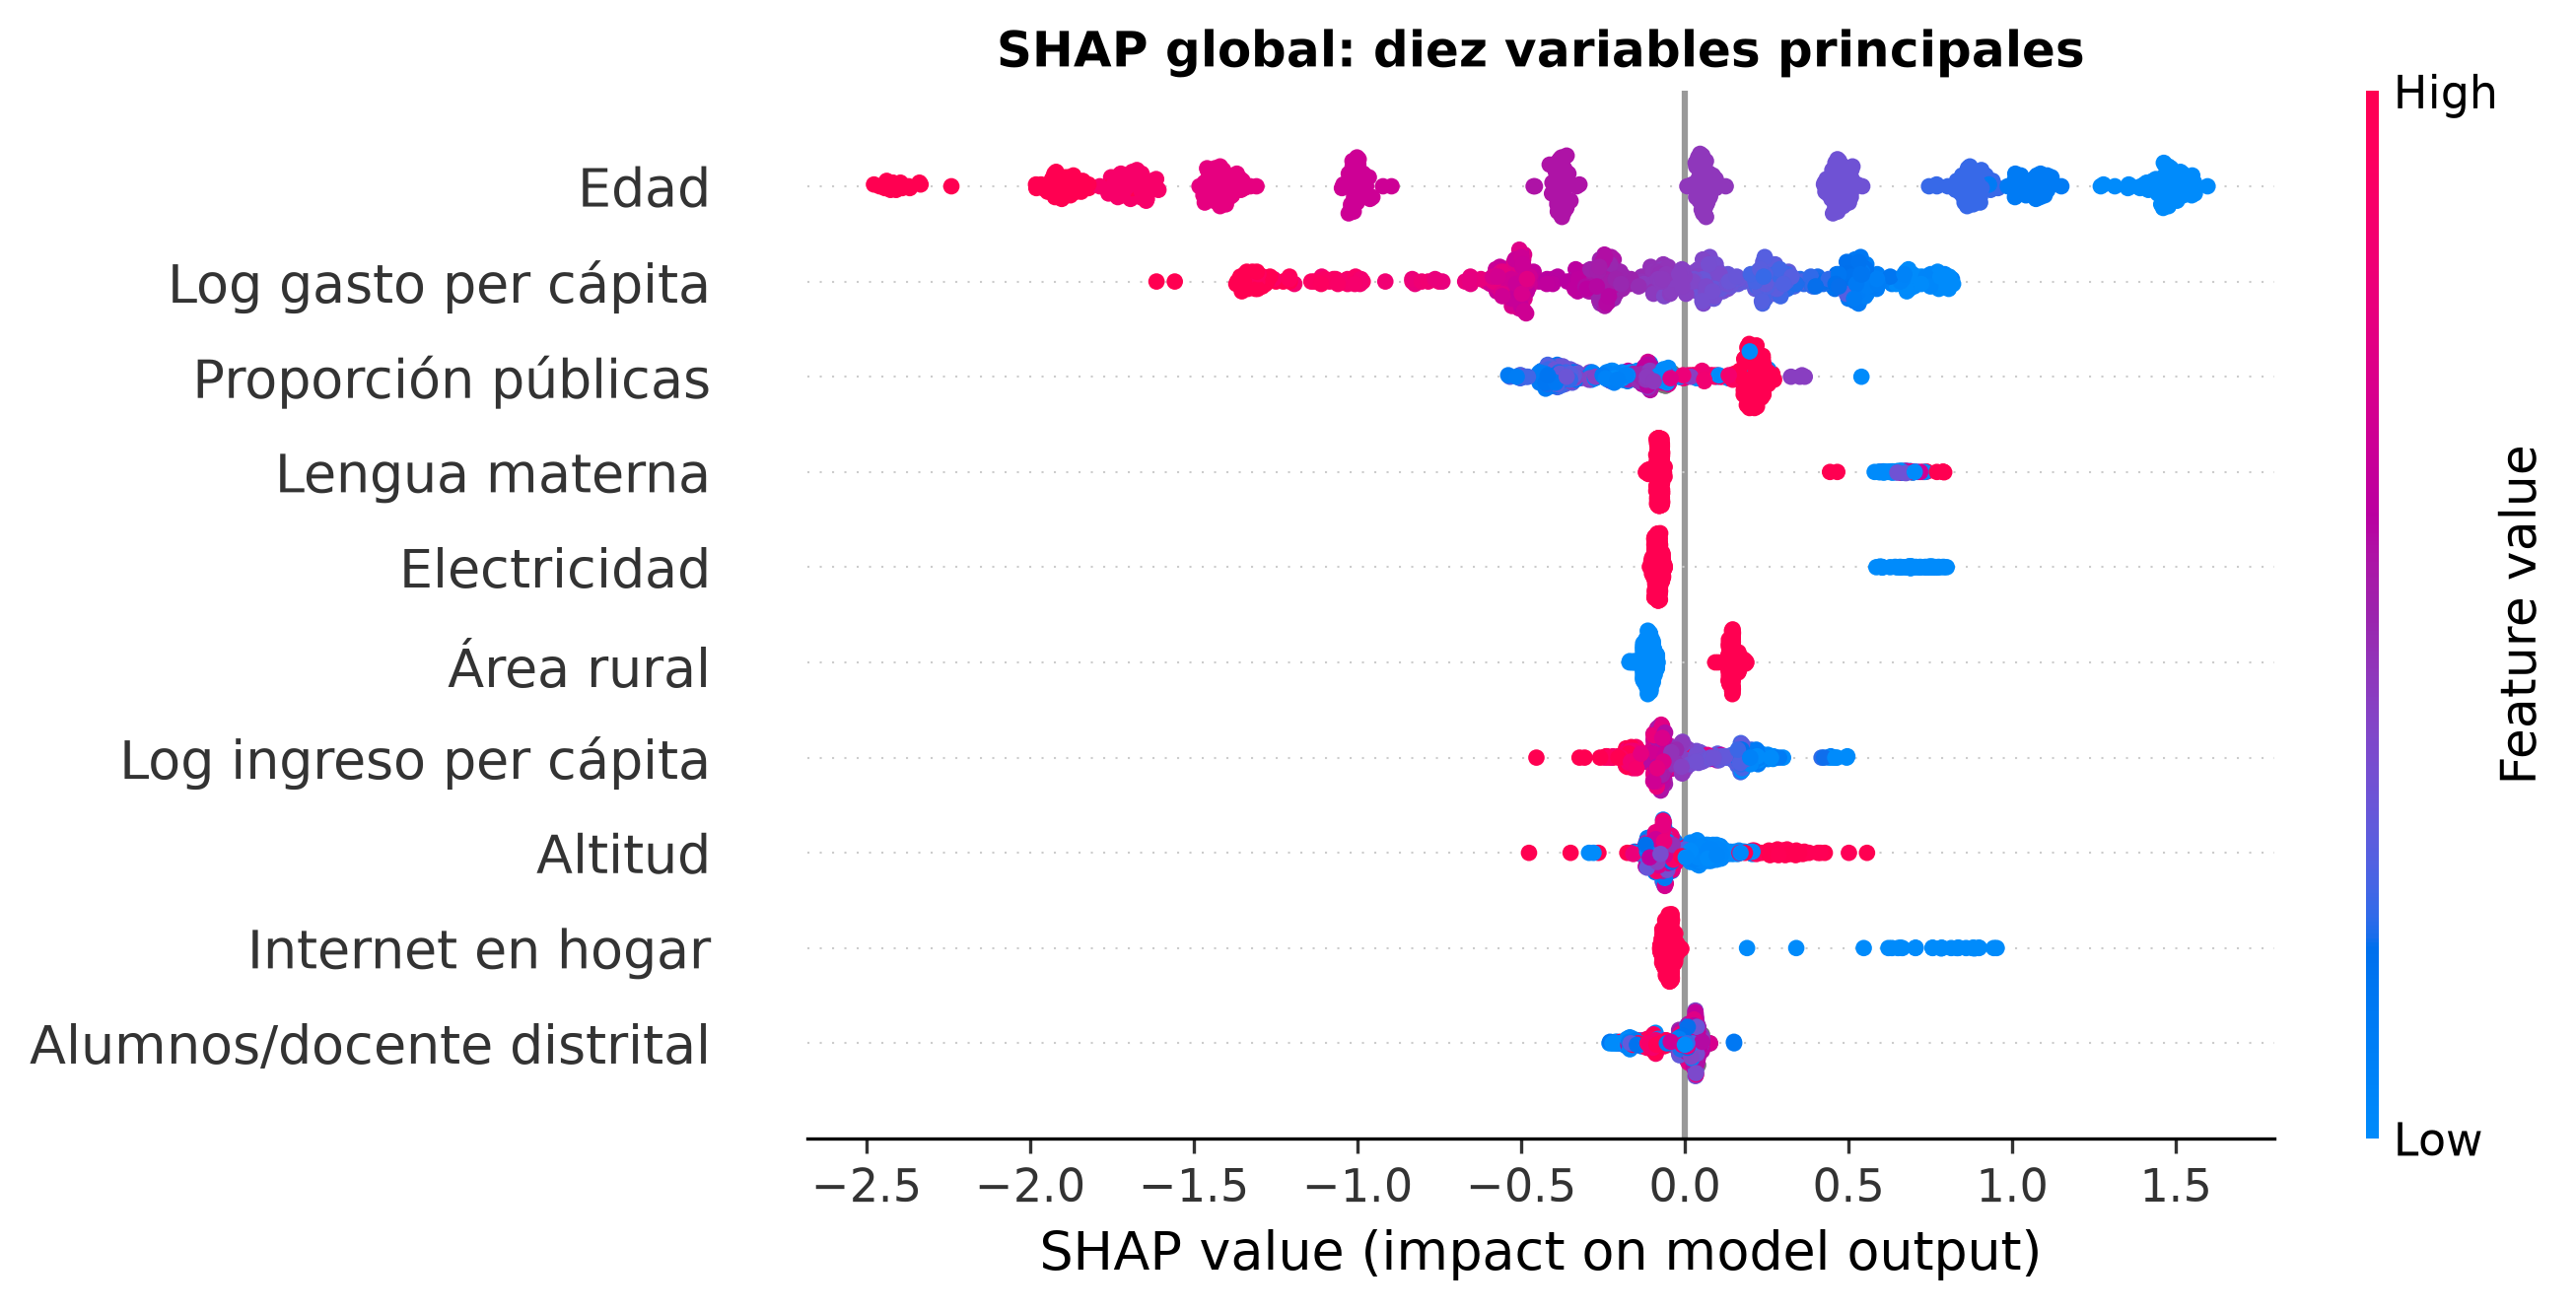

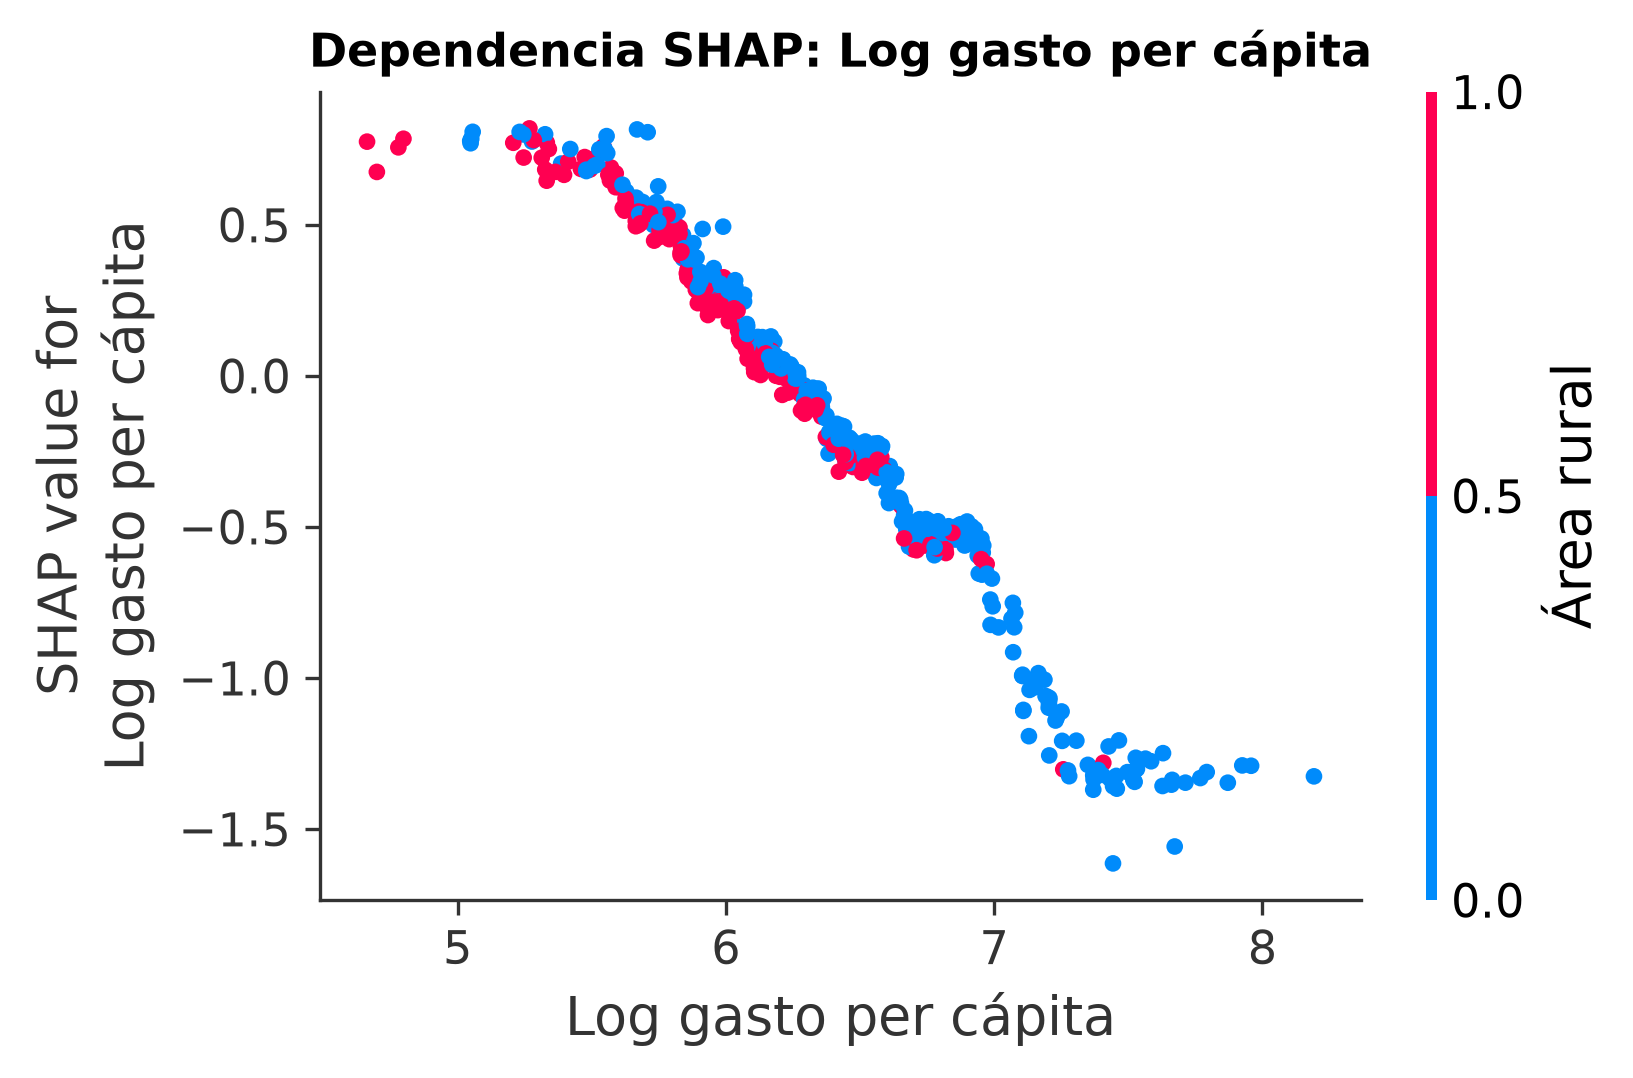

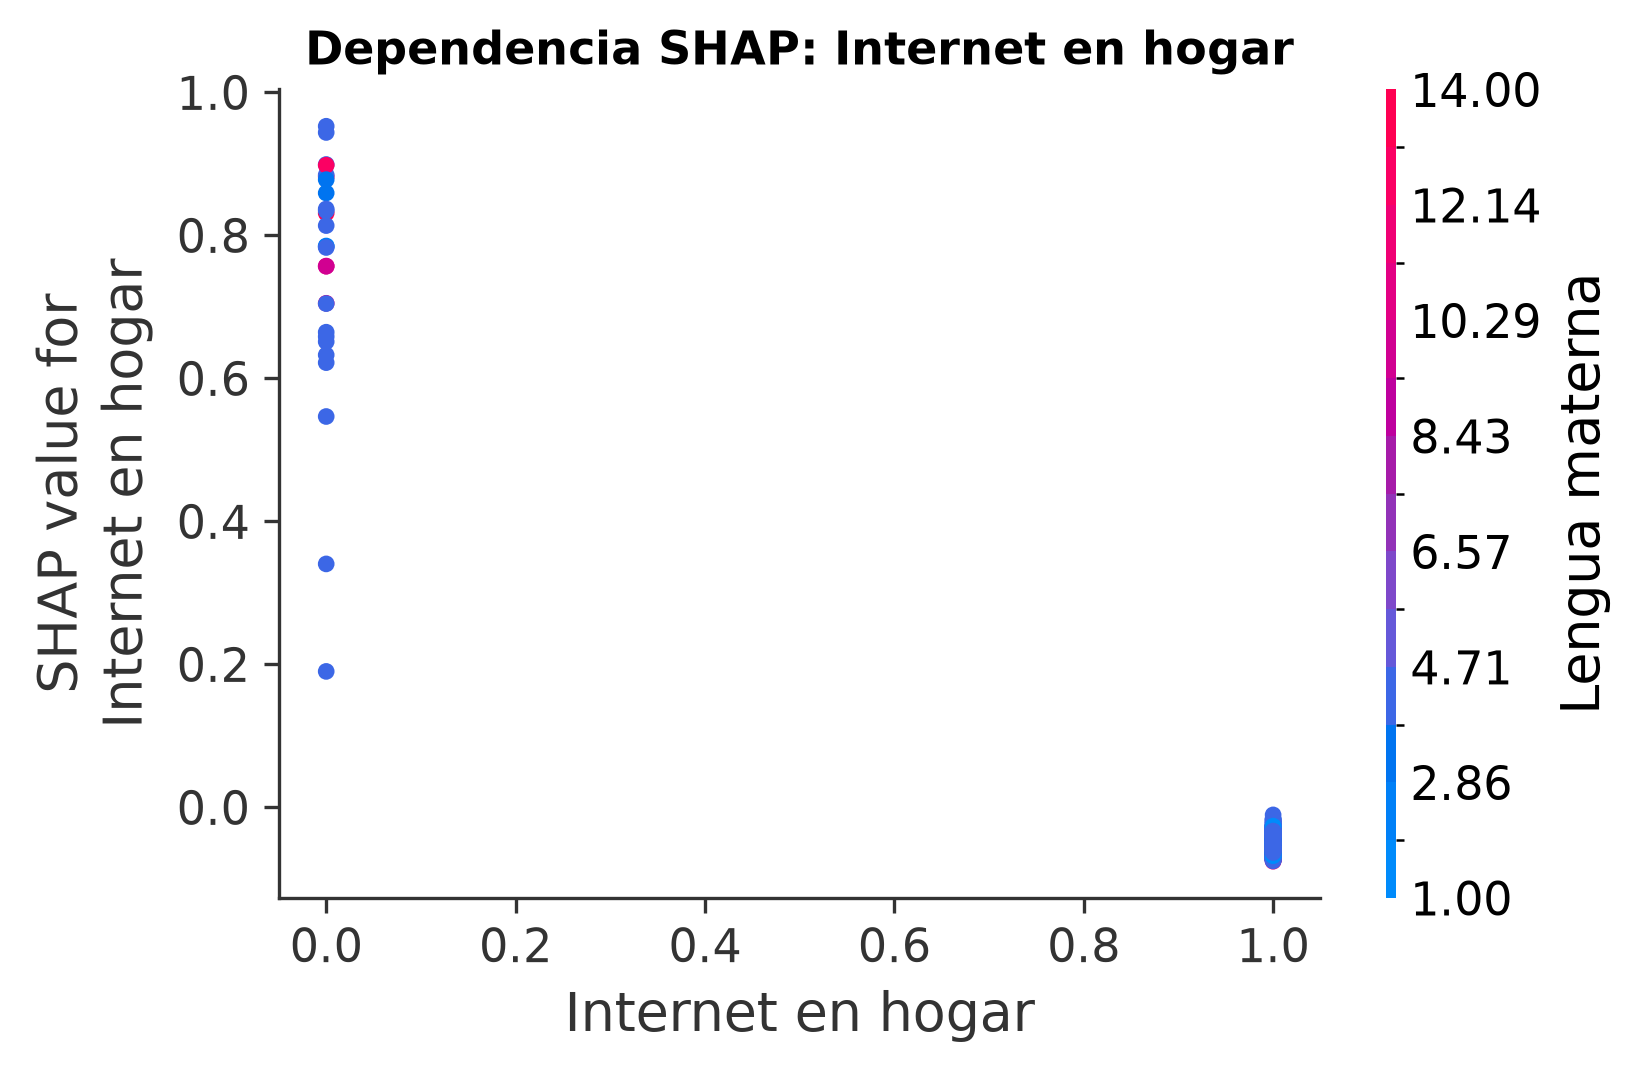

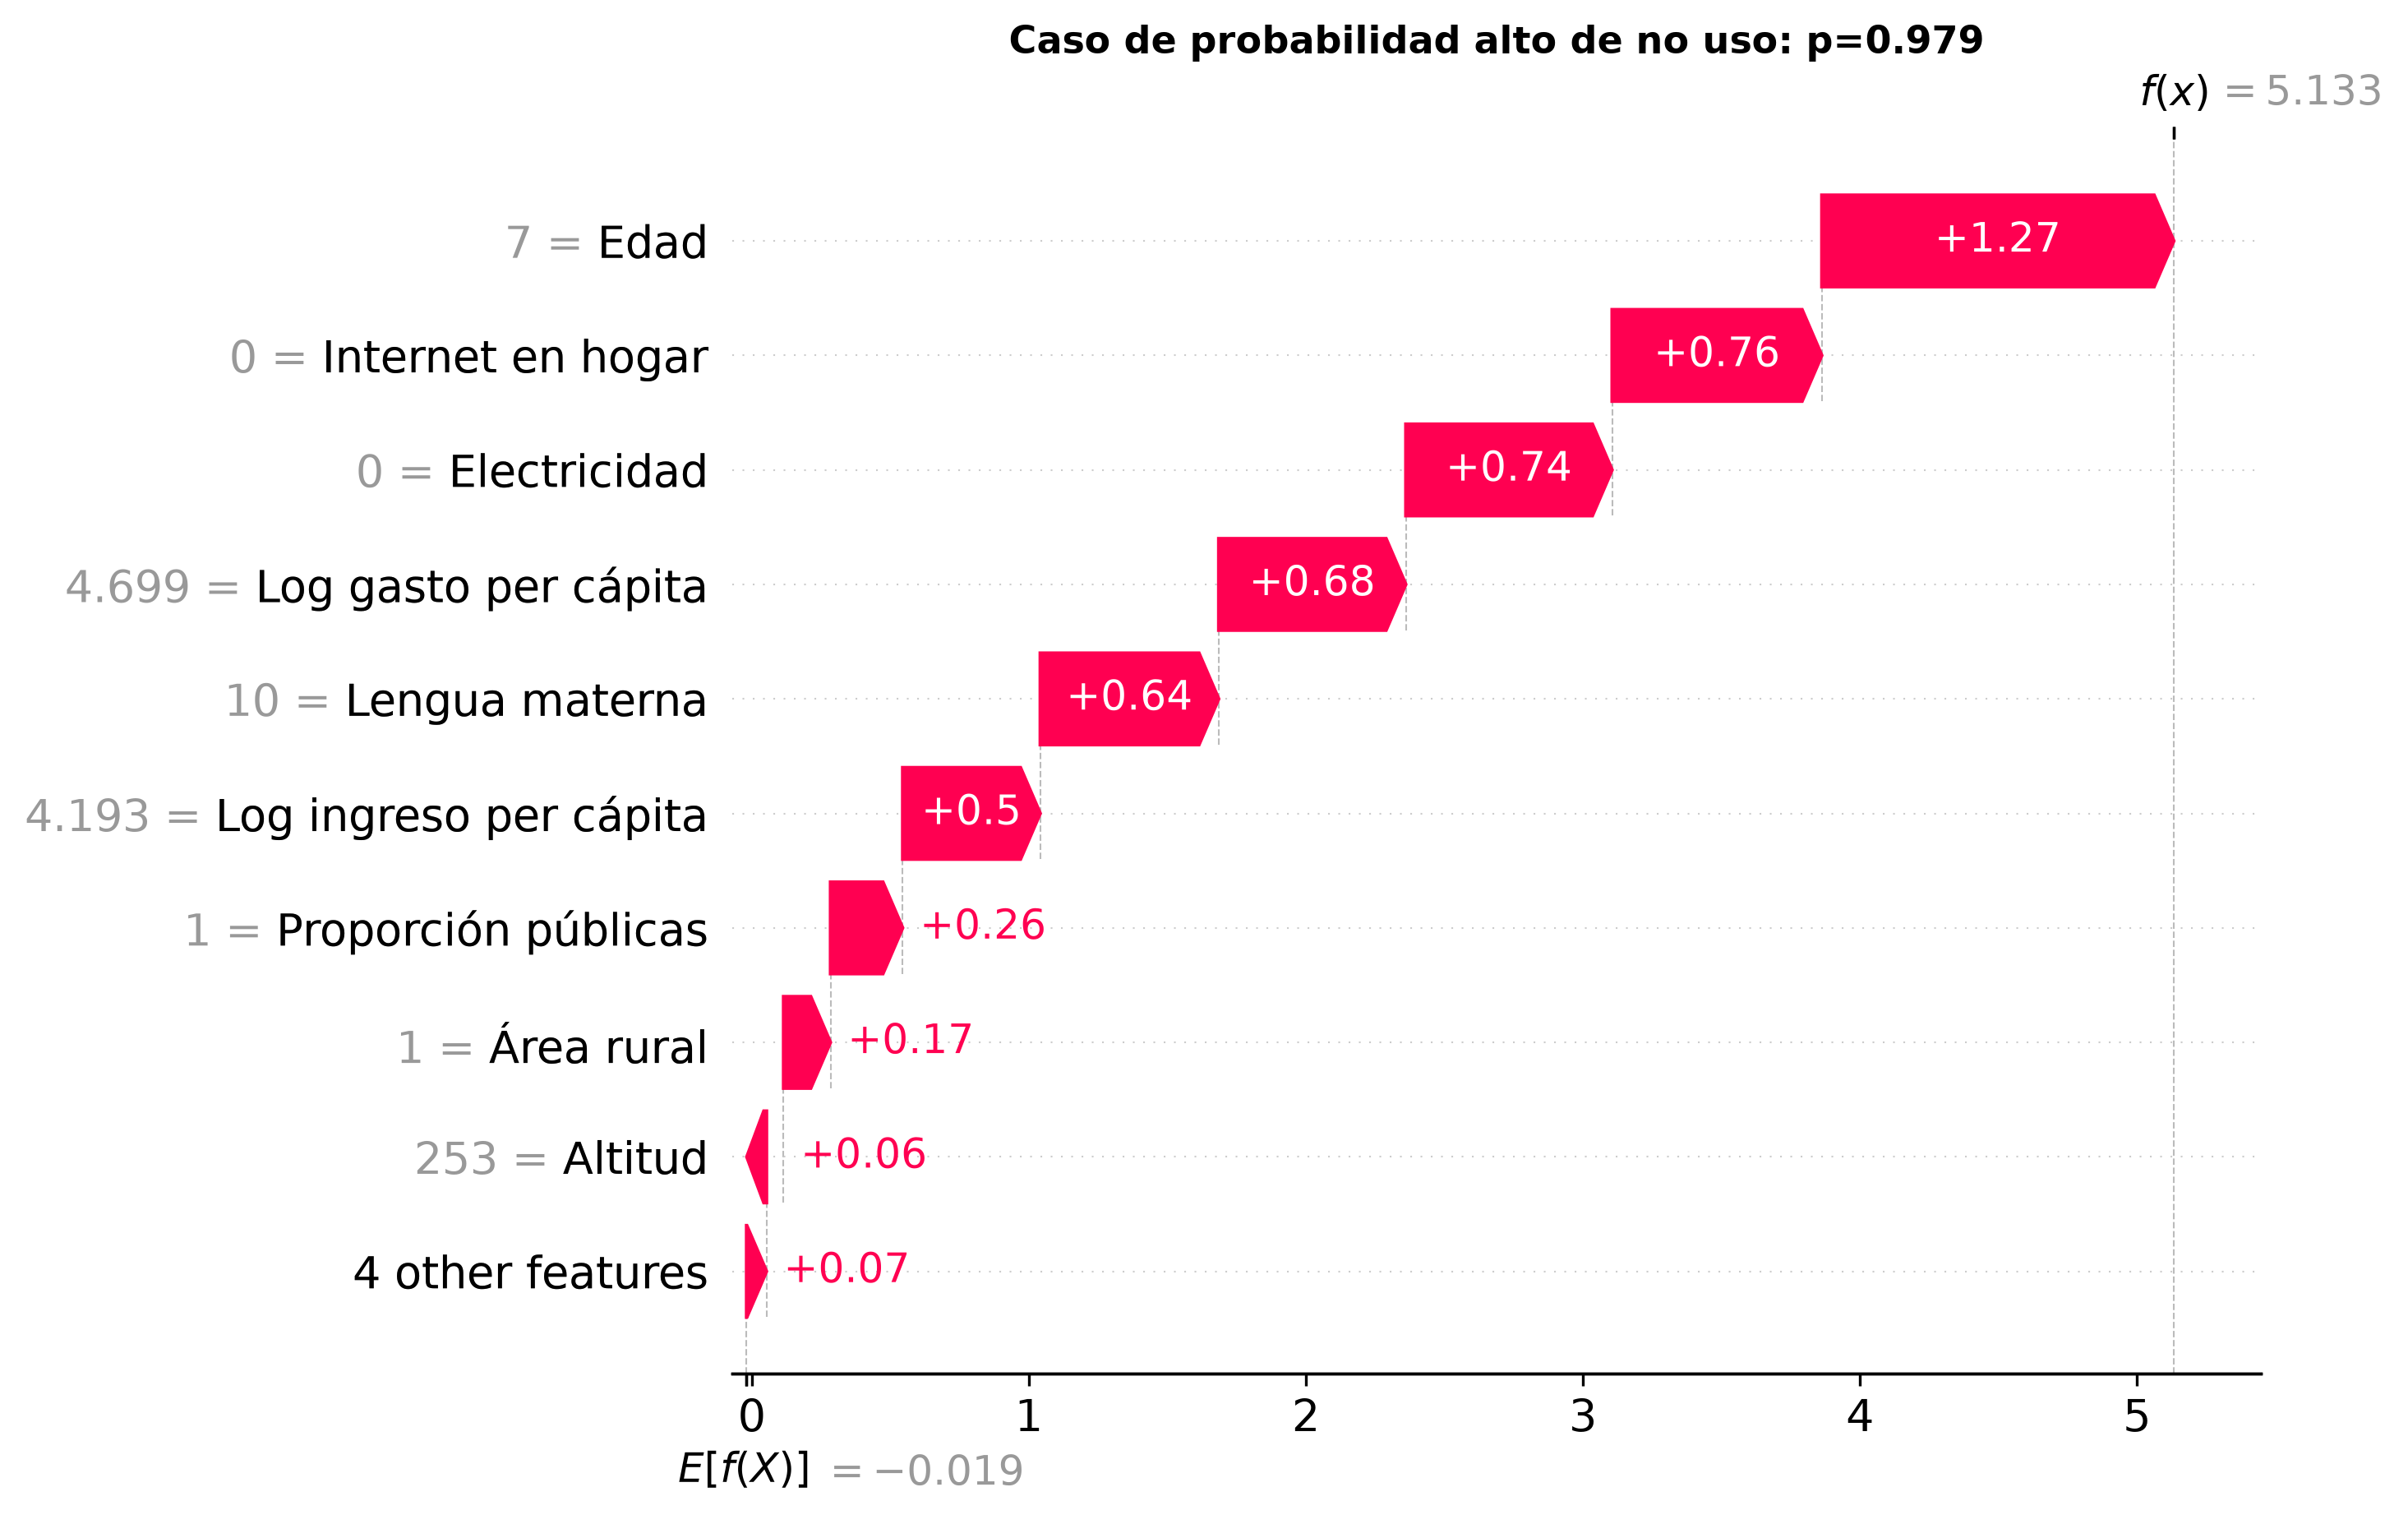

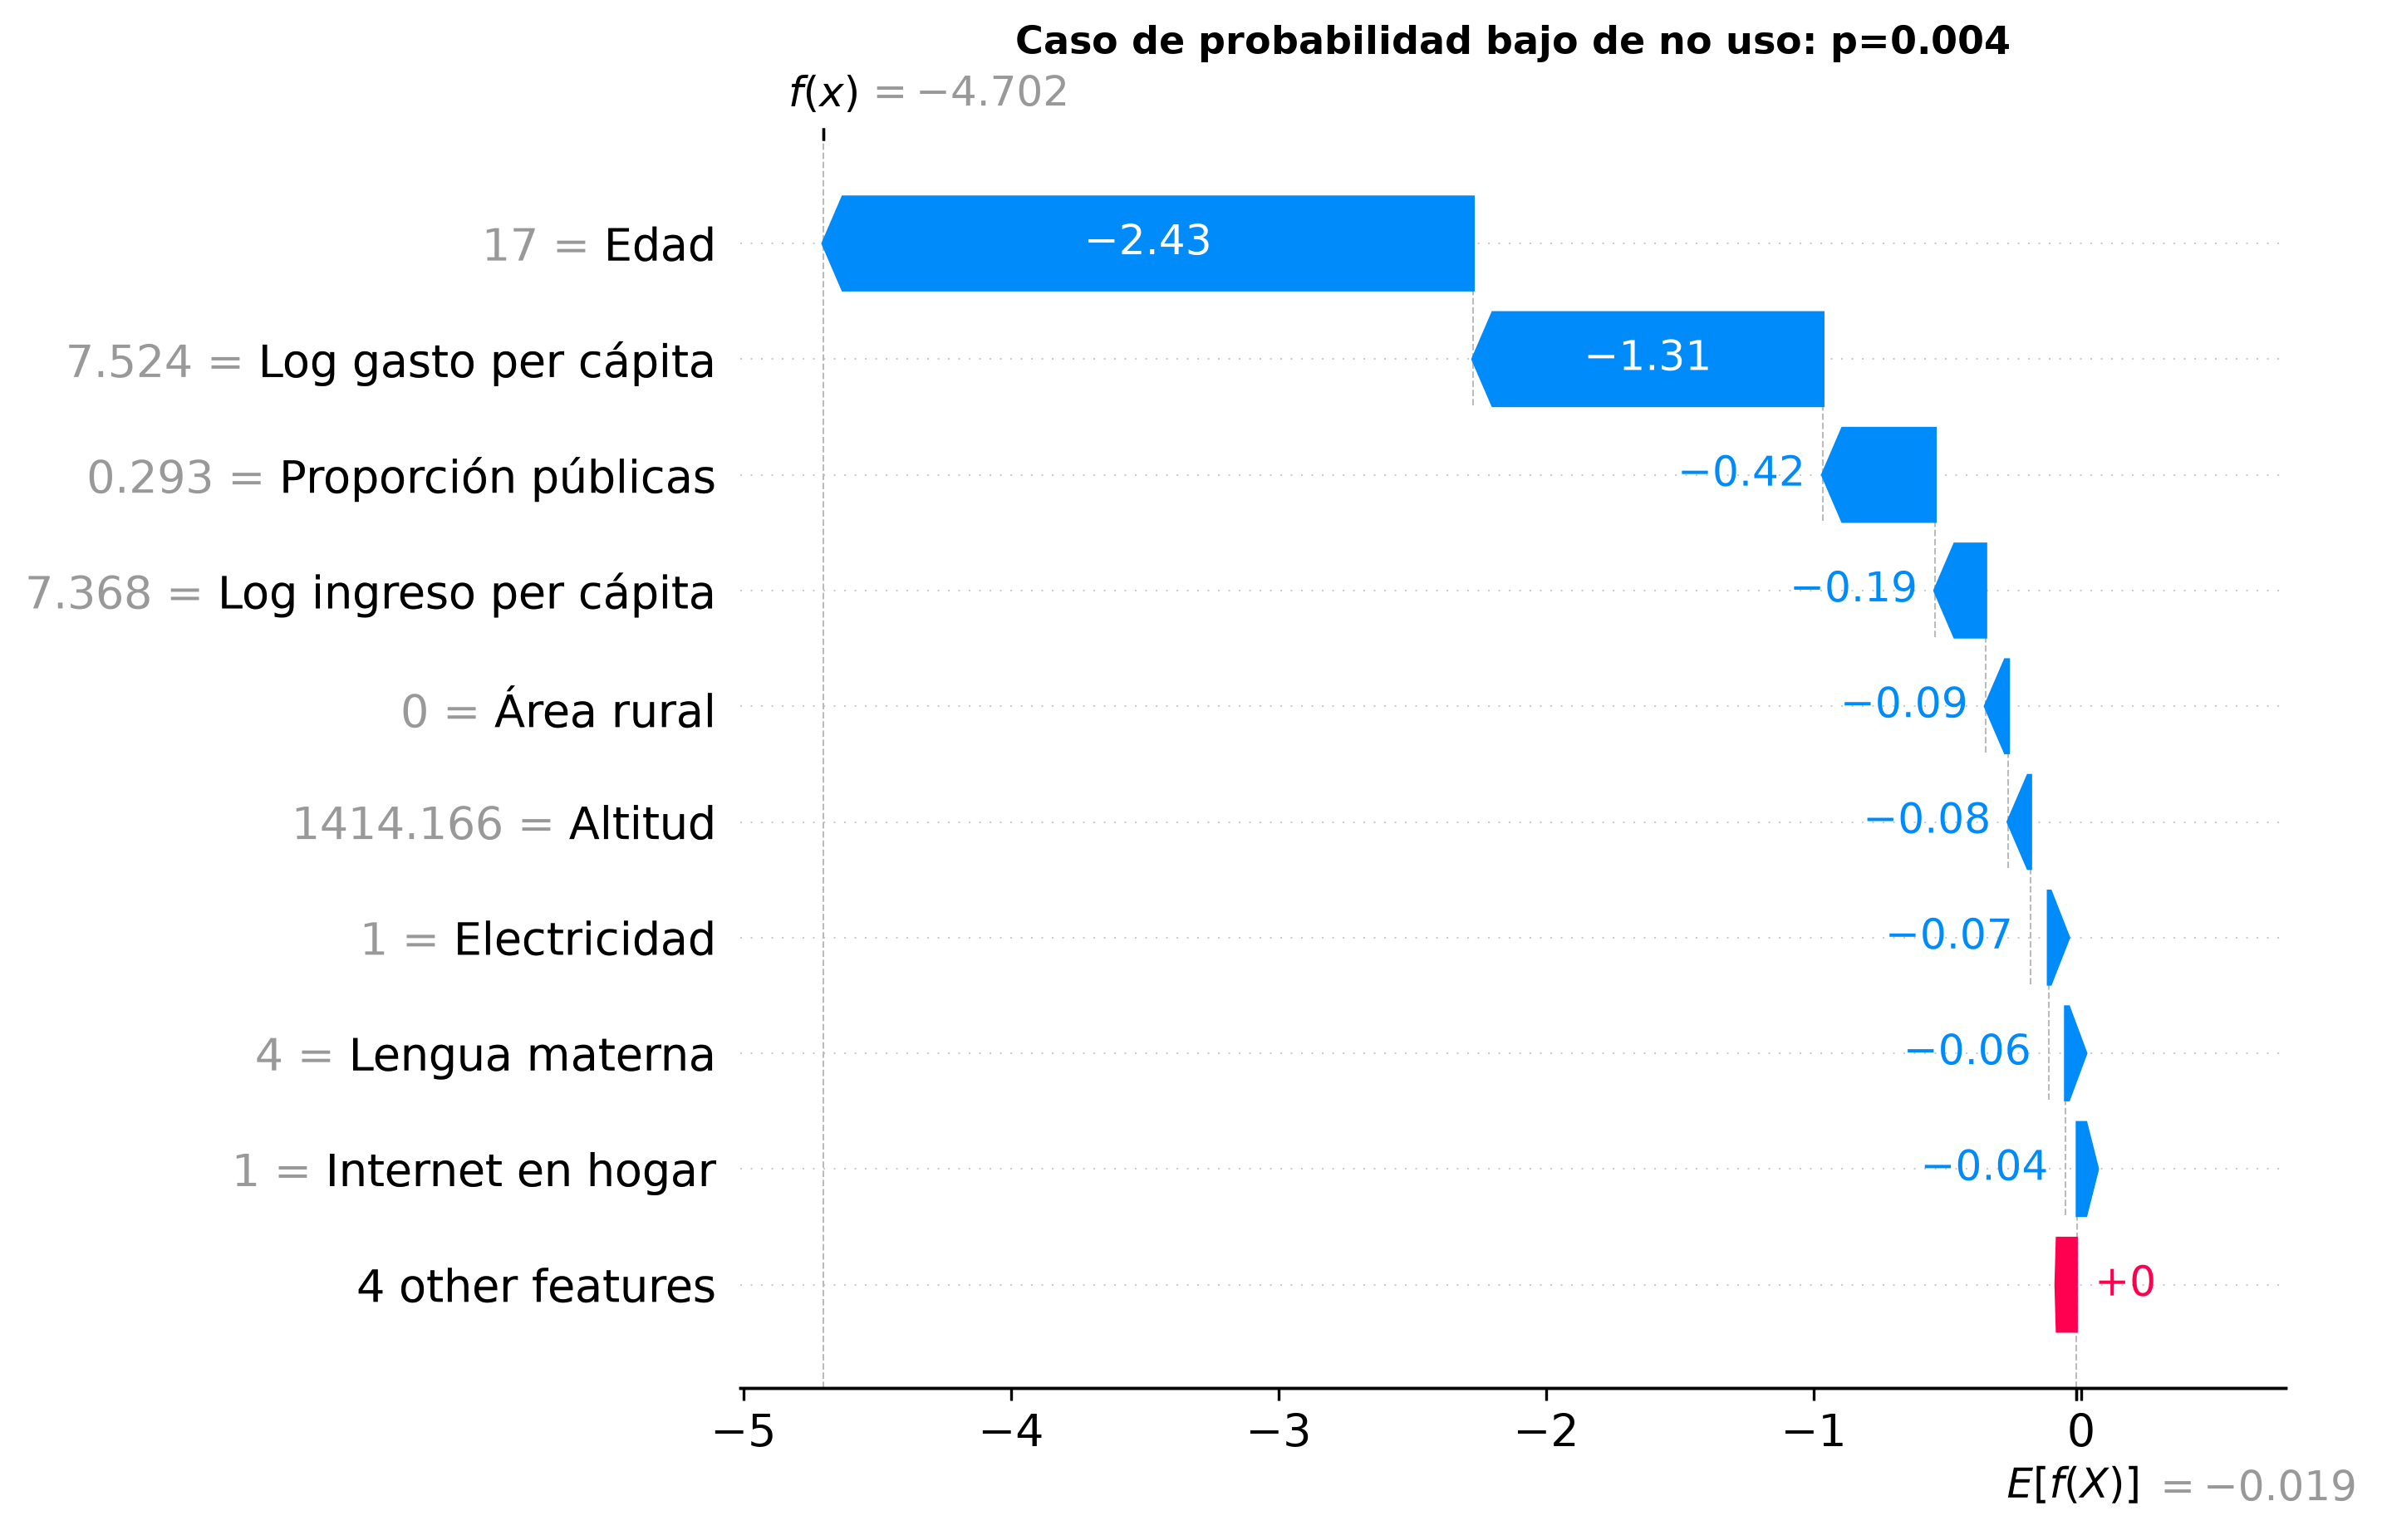

In [2]:
run_script('run_analysis.py','--phase','shap')
r=results()
print('Ganador:',r['supervised']['winner'],'| unidades:',r['shap']['units'])
print('Residuo aditividad:',r['shap']['max_additivity_residual'])
table('shap_importance.csv')
for name in ['shap_beeswarm.png','shap_dependence_1.png','shap_dependence_2.png','shap_waterfall_alto.png','shap_waterfall_bajo.png']: show(name)

## Interacciones del árbol
Las dependencias coloreadas no prueban por sí solas una interacción. Aquí se calculan valores de interacciónTreeSHAP: el par aporta2φij al score. Los pares se seleccionan exploratoriamente por contribución absoluta, sin afirmar significación.

{'model': 'XGBoost', 'winner': 'CatBoost', 'role': 'Análisis complementario; no sustituye al ganador', 'n_explained': 180, 'sample_seed': 42, 'units': 'log-odds antes de calibrar', 'background': 'TreeSHAP tree_path_dependent: cobertura de hojas ajustada en desarrollo', 'max_additivity_residual': 2.384185791015625e-06, 'max_interaction_row_residual': 1.9073486328125e-06, 'note': 'El par aporta 2*phi_ij al score; las interacciones son propiedades predictivas del árbol ajustado, no efectos causales ni pruebas de significación. La selección de pares es exploratoria posterior al ajuste.'}


,variable_1,variable_2,mean_abs_pair_contribution
0,altitud,prop_publicas,0.038718
1,altitud,ratio_alumnos_docente,0.028175
2,internet_hogar,log_gasto_pc,0.025225
3,log_ingreso_pc,log_gasto_pc,0.022771
4,log_gasto_pc,prop_publicas,0.020290
5,altitud,log_gasto_pc,0.018519
6,log_ingreso_pc,prop_publicas,0.014942
7,log_gasto_pc,ratio_alumnos_docente,0.014395
8,lengua_materna,altitud,0.013843
9,rural,log_gasto_pc,0.012627


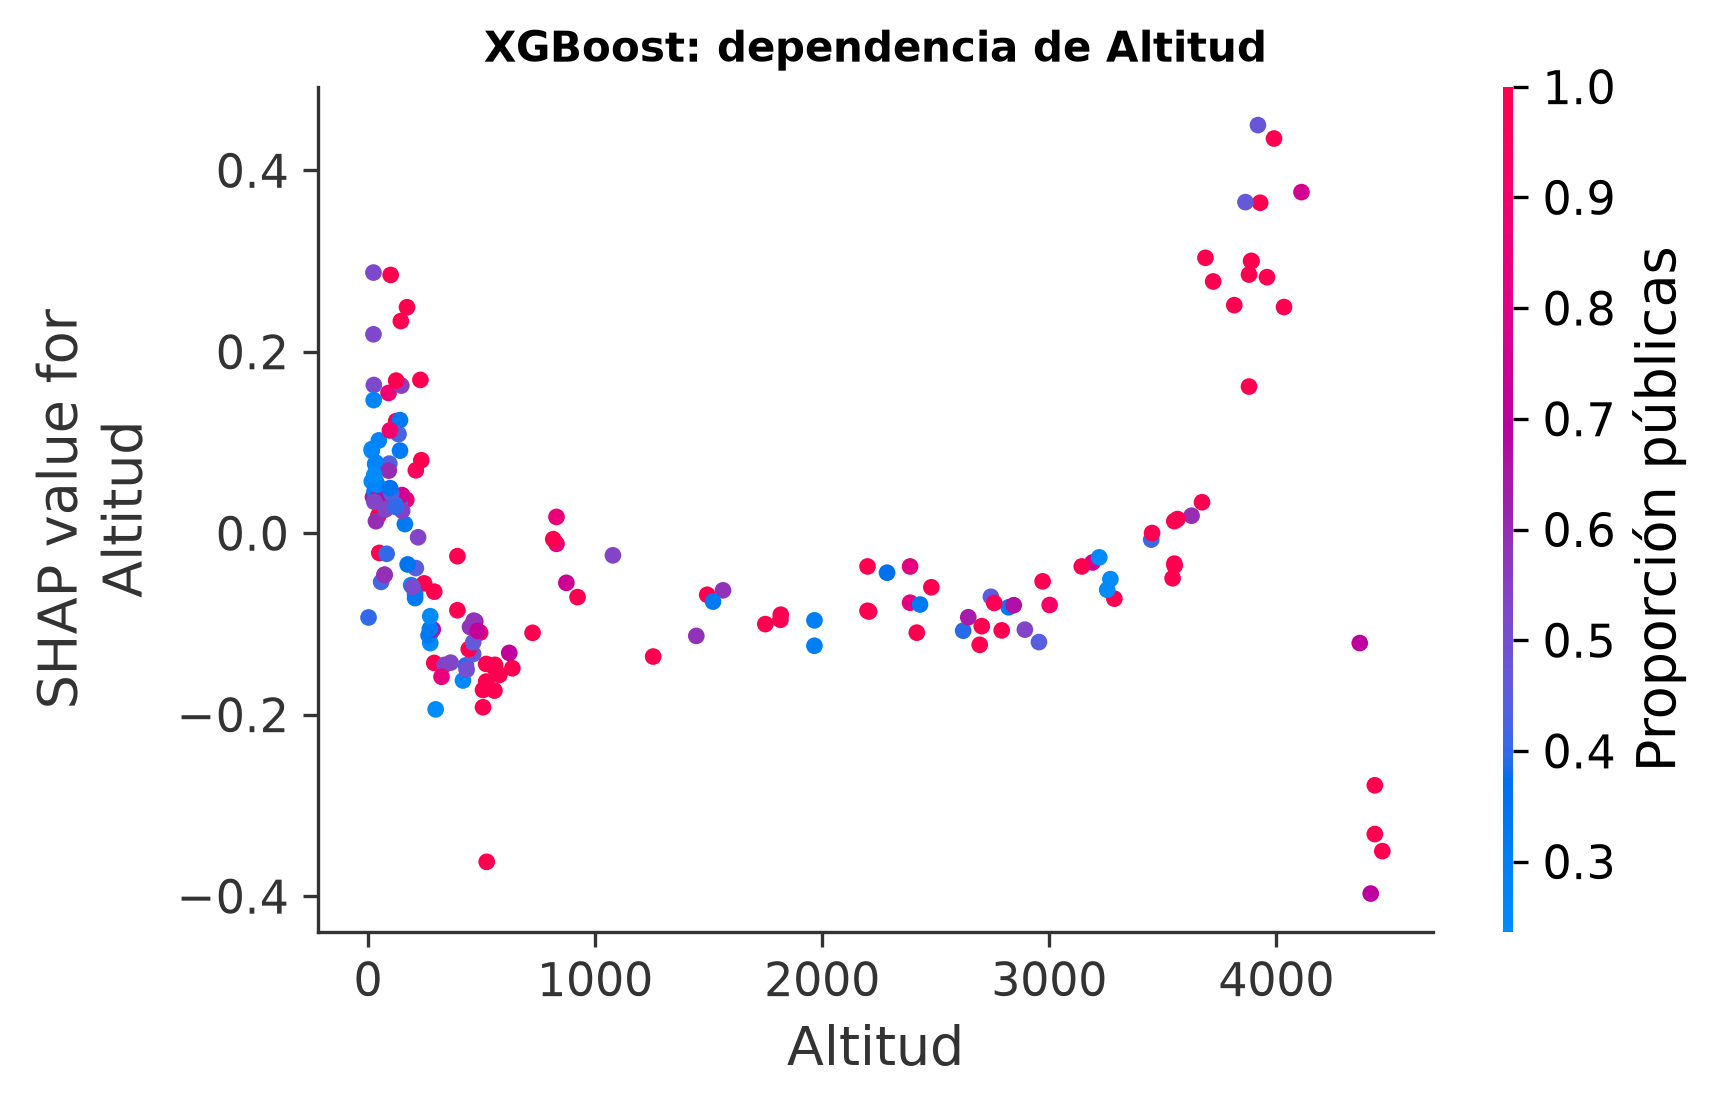

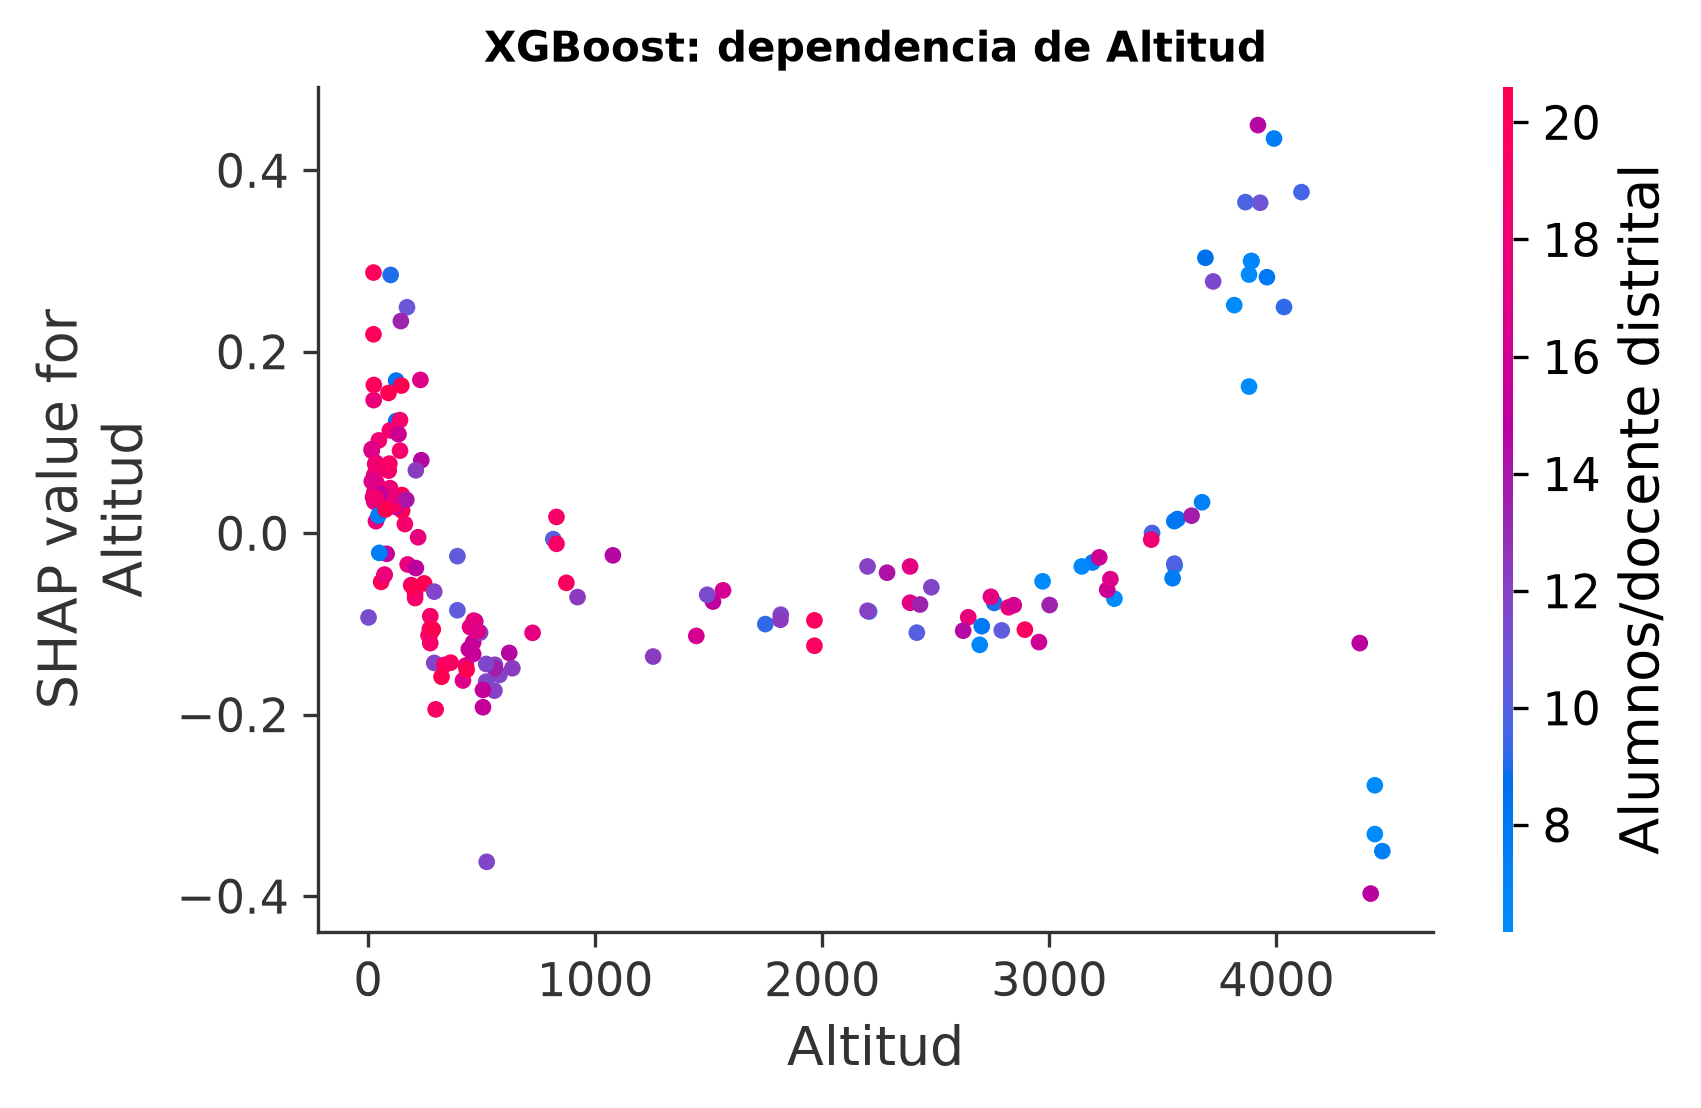

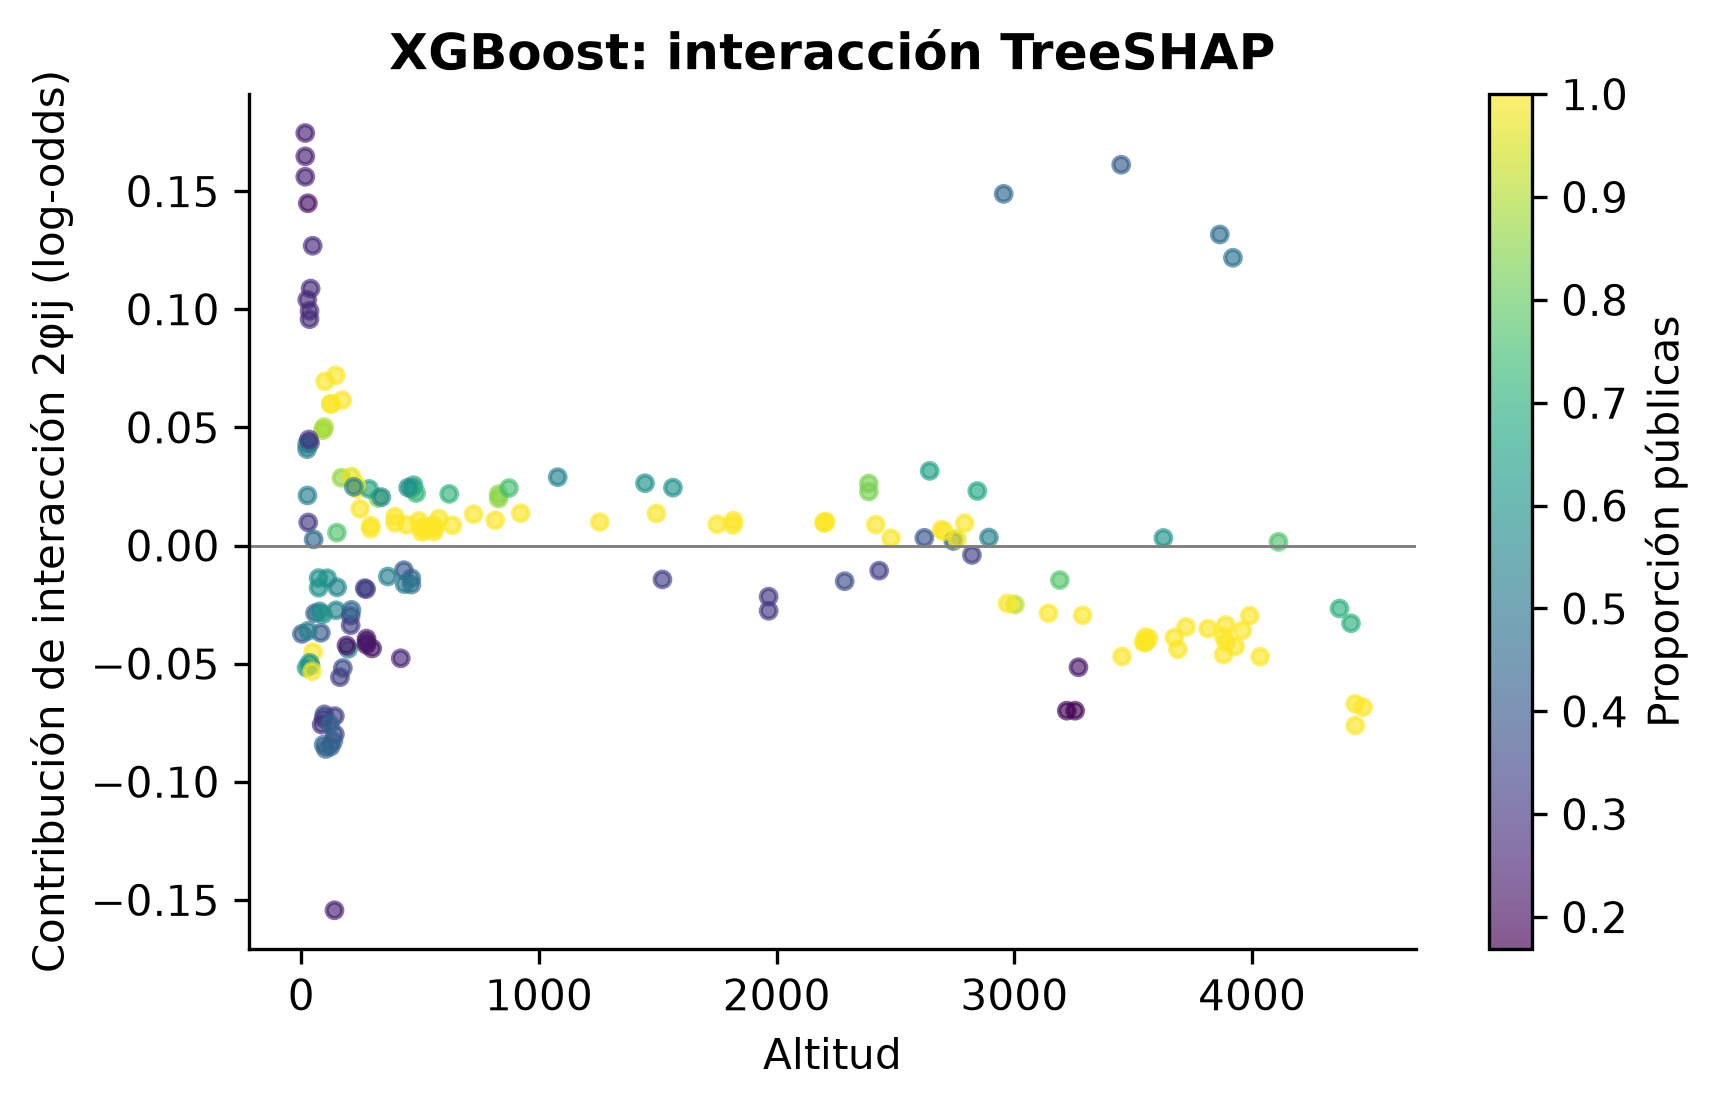

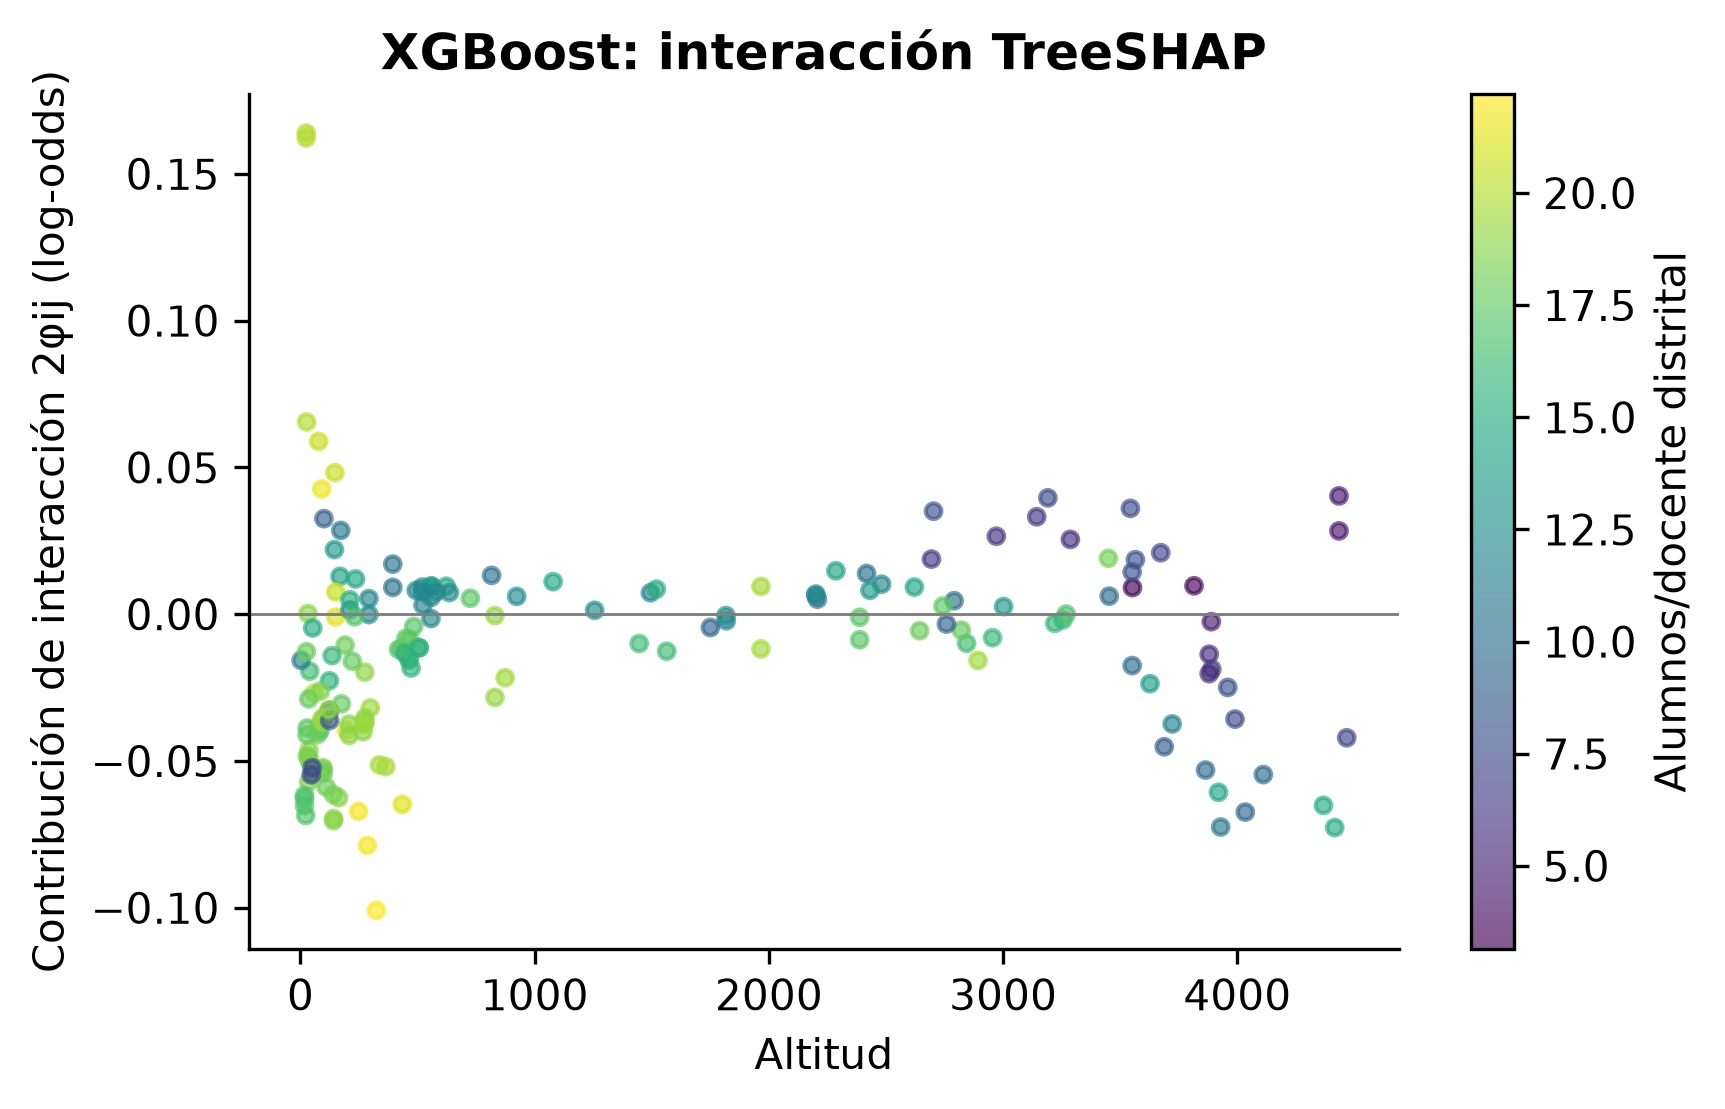

In [3]:
print({k:v for k,v in r['nonlinear_shap'].items() if k!='pairs'})
table('shap_interactions_xgboost.csv')
for name in ['shap_nonlinear_dependence_1.png','shap_nonlinear_dependence_2.png','shap_interaction_1.png','shap_interaction_2.png']: show(name)

## Conclusión
Explique qué modelo produce cada figura y cómo se reconstruye su score. Una contribución predictiva no es un efecto causal ni un diagnóstico de habilidades digitales. Los casos extremos ilustran mecanismos del modelo y no representan al conjunto de estudiantes.